# Solving Inverse Problem using Connectome Spectrum Electromagnetic Tomography (CSET)

In this section we will solve the inverse problem using our new method CSET. This requires the eeg measurements, the forward solution and the connectome spectrum transform (prior). <br>
The method solves the following problem: $$\vec{x}^* = \text{argmin}_{\vec{x}} \lVert A\vec{x}-b \rVert_2^2 + \lambda_1 \lVert W\vec{x} \rVert_2^2 + \lambda_2 \lVert F\vec{x}\rVert_1$$
where
- $\vec{x}^* \in \mathbb{R}^n$ is the reconstructed brain activity.
- $\vec{x} \in \mathbb{R}^n$ is the brain activity.
- $\vec{b} \in \mathbb{R}^m$ are the eeg measurements.
- $A \in \mathbb{R}^{m\times n}$ is the forward matrix.
- $W \in \mathbb{R}^{n \times n}$ are the source covariances. Usually weighted to give more freedom to deep sources
- $F \in \mathbb{R}^{n \times n}$ is the connectome spectrum transform.
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert F\vec{x} \rVert_1$ imposes the connectome spectrum of $\vec{x}$ to be sparse and $\lambda$ 

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

In [2]:
# configuration
config = mm.io.read_config("../configurations/simf.yml")
sub    = config["SUBS"][0]
sample = config["SAMP"][8]

# data
data = mm.io.read_dataset(sub, "fwd", "cst", "eeg_inv", "gt", sample=sample)
#data["eeg_inv"] = data["eeg_bad"]       # Correct this stuff once finished with it

# features
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                              # forward matrix

sfreq = data["eeg_inv"].info["sfreq"]

_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

print(f"50% rising phase time: {t_half:03}")
print(f"Peak time: {t_peak:03}")

50% rising phase time: 0.504
Peak time: 0.552


#### 🌟 Visualize ground truth

In [3]:
try:
    mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)
except KeyError as e:
    print("\033[91mNo ground truth available.\033[0m")

Widget(value='<iframe src="http://localhost:38877/index.html?ui=P_0x752c8fe5bb30_0&reconnect=auto" class="pyvi…

In [4]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(data["gt"].data[:,pt]), cmap="reds").show()

Widget(value='<iframe src="http://localhost:38877/index.html?ui=P_0x752c8fe696a0_2&reconnect=auto" class="pyvi…

In [5]:
mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,pt])

#### 🌟 Visualize EEG time series

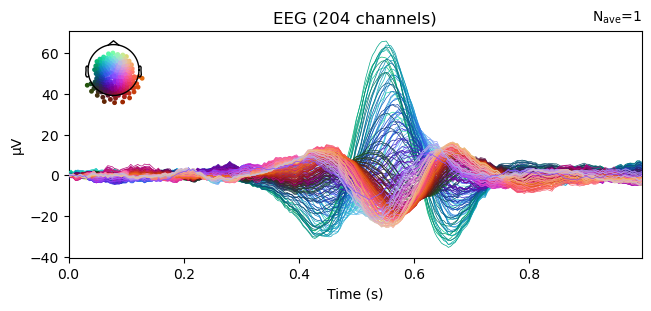

In [6]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

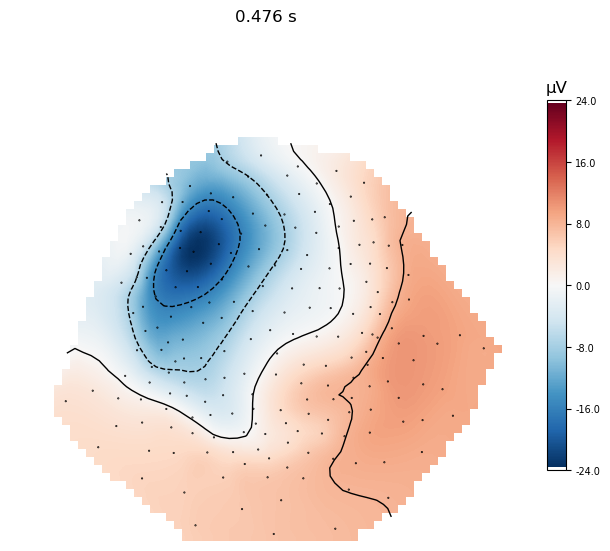

In [7]:
times = [0.476]
_ = data["eeg_inv"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

## Select a Time point

🛠️ <font color=violet>**Select a time window to reconstruct**</font>: One time sample takes around 1 second to reconstruct.
- Window size (`win_size`): time window around EEG peak in [s]

Number of samples: 24


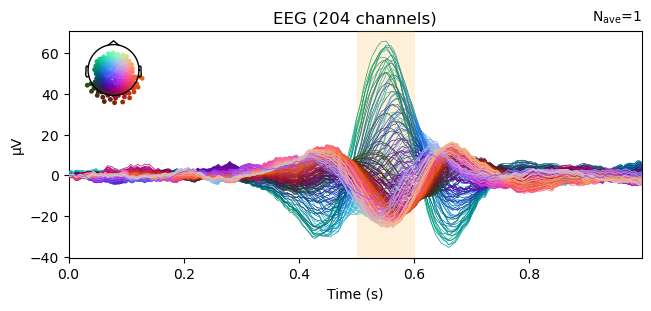

In [8]:
win_size = 0.1      # window size in [s], if None take the 50% rising phase and peak phase only

if win_size is not None:
    dt = int(win_size * sfreq /2)
    Y_  = data["eeg_inv"].data[:, pt-dt:pt+dt]

    t_start  = t_peak-(win_size/2)
    t_end    = t_peak+(win_size/2)
    idx_half = int((t_half-t_start)*sfreq)
    idx_peak = int((t_peak-t_start)*sfreq)

    highlight = [t_start, t_end]

else:
    Y_ = data["eeg_inv"].data[:, [ht,pt]]

    idx_half = 0
    idx_peak = 1

    highlight = [t_half-1e-3, t_half+1e-3], [t_peak-1e-3, t_peak+1e-3]

print(f"Number of samples: {Y_.shape[1]}")
_ = data["eeg_inv"].plot(highlight=highlight)

## Solve The Inverse Problem with CSET

🛠️ <font color=violet>**Select CSET parameters**</font> 
- $\lambda$ (`lam`): regularizer parameter (influences the connectome spectrum sparsity)

In [9]:
alpha = 0.99       # L1/L2 regularizer
dw = 1/2             # depth weighting
cut_freq = None    # cst cut off frequency
scale = 1e0        # pyxu does not optimize for small scale so this scales data to big numbers (for optimization) and then descales (for values)

⚙️ <font color=green>**Solve inverse problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [10]:
# frequency cutoff
if cut_freq is not None:
    cst = data["cst"][:cut_freq,:]
else:
    cst = data["cst"]

# regularizers
lambda1 = 1 - alpha
lambda2 = alpha
gamma   = lambda1 / (1+lambda2)**(1/2)

# standardize
Ynorms = np.linalg.norm(Y_, axis=0)
Y      = Y_/Ynorms[None,:]

L      = fwd - np.mean(fwd, axis=0)
Lnorms = np.linalg.norm(L, axis=0)**dw
L      = L / Lnorms[None,:] 

# component-wise transformation
L = L @ cst.T

# define artificial data set
L = (1 + lambda2)**(-1/2) * np.vstack([L, lambda2**(1/2)*np.eye(L.shape[1])])
Y = np.vstack([Y, np.zeros((L.shape[1], Y.shape[1]))])

# pyxu components
L     = pxa.LinOp.from_array(L)
prior = gamma*pxo.L1Norm(dim_shape=cst.shape[0])
recon = np.zeros((cst.shape[1], Y.shape[1]))
sc    = pxst.MaxIter(1000)

# ---- optimization ----
for t in range(Y.shape[1]):
    y     = Y[:,t]
    s_hat = np.random.random(L.dim_shape[0])*10**(-9)

    likelihood = pxo.SquaredL2Norm(dim_shape=L.codim_shape).argshift(-y)*L
    likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

    solver = PGD(f=likelihood, g=prior, show_progress=False)

    solver.fit(x0=s_hat, stop_crit=sc)

    s_hat      = solver.solution().squeeze()
    s_hat      = (1+lambda2)**(1/2) * s_hat      # enet correction
    recon[:,t] = (cst.T @ s_hat) * Ynorms[t] /scale

#### <font color=yellow>🌟</font> Visualize reconstruction

In [11]:
viz = np.abs(recon) / (np.max(np.abs(recon), axis=0)+1e-15)
mm.viz.plot_brain_time_series(data["fwd"]["src"], viz, t_start=t_start, sfreq=sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:38877/index.html?ui=P_0x752c685676b0_3&reconnect=auto" class="pyvi…

In [129]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(recon[:,idx_peak]), cmap="reds").show()

Widget(value='<iframe src="http://localhost:39481/index.html?ui=P_0x7d292d4e4860_70&reconnect=auto" class="pyv…

In [128]:
mm.viz.plot_spectrum(data["cst"]@recon[:,idx_peak])

#### 💾 Save result

In [ ]:
fname  = f"{sub}_enet-{alpha}"
folder = Path(config["MM_DIR"])/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving source time course of {sub}, {sample}")
vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
stc = mne.SourceEstimate(recon, vertices, tmin=t_start, tstep=1/sfreq, subject=sub)
stc.save(folder/fname, overwrite=True, verbose="warning")

Saving source time course of sub-pat18, 


# Applying CSET on dataset

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Configuration file (`config`)
- `subjects`: list of subjects to process
- `samples`: list of samples to process


🎚️ **<font color=pink>Parameters</font>**
- Regularizer parameter (`lam`)
- Time window size (`win_size`)
- Depth Weighting scale (`dw`)
- Scale (`scale`)

In [3]:
# config
config   = mm.io.read_config("../configurations/simf.yml")
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])
fname    = lambda sub, samp, alpha: mm_dir/sub/"inv"/f"{sub}_{samp}_enet-{alpha}"

# parameters
win_size = 0.1 
alpha    = 0.99 
dw       = 1/2
scale    = 1

In [4]:
for sub in config["SUBS"]:
    for samp in config["SAMP"]:
        try: 
            data = mm.io.read_dataset(sub, "eeg_inv", "fwd", "cst", sample=samp)
            stc  = mm.enet(data["eeg_inv"], data["fwd"], data["cst"], alpha, dw, win_size, scale, sub)
        except Exception as e:
            print(f"\033[91mSkipped {sub}, {samp} due to {e}\033[0m")
            continue

        file = fname(sub, samp, alpha)
        if not file.parent.exists():
            file.parent.mkdir()

        stc.save(file, overwrite=True, verbose="warning")
        print(f"\033[92m{sub}, {samp} successfully reconstructed\033[0m")

vepcon_sub-10, sample1 successfully reconstructed
vepcon_sub-10, sample2 successfully reconstructed
vepcon_sub-10, sample3 successfully reconstructed
vepcon_sub-10, sample4 successfully reconstructed
vepcon_sub-10, sample5 successfully reconstructed
vepcon_sub-10, sample6 successfully reconstructed
vepcon_sub-10, sample7 successfully reconstructed
vepcon_sub-10, sample8 successfully reconstructed
vepcon_sub-10, sample9 successfully reconstructed
vepcon_sub-10, sample10 successfully reconstructed
vepcon_sub-10, sample11 successfully reconstructed
vepcon_sub-10, sample12 successfully reconstructed
vepcon_sub-10, sample13 successfully reconstructed
vepcon_sub-10, sample14 successfully reconstructed
vepcon_sub-10, sample15 successfully reconstructed
vepcon_sub-10, sample16 successfully reconstructed
vepcon_sub-10, sample17 successfully reconstructed
vepcon_sub-10, sample18 successfully reconstructed
vepcon_sub-10, sample19 successfully reconstructed
vepcon_sub-10, sample20 successfully rec